# How much labelled data does pretraining save?
## Classical filter banks vs. fine-tuned ResNet-18 on GTSRB

**COMS4036A Computer Vision · Honours project · group nwk_p**
Khuselo Sofohlo (2729931) · Wakhiwe Ndzimandze (2694083) · Niel Grobler (2690034)

**Question:** As the amount of labelled training data shrinks, how does the advantage of an ImageNet-pretrained CNN over a classical feature-based pipeline change, on traffic-sign classification?

**Hypothesis:** The pretrained CNN keeps a higher score at every training-set size, and the gap widens most sharply when data is scarcest.

**Design:** Two approaches are compared under one protocol in which training-set size is the only thing that changes:

- **Classical:** grayscale → 38-filter Gaussian-derivative bank (the MR8 family) → 4×4 spatial pooling → logistic regression.
- **Transfer learning:** ImageNet-pretrained ResNet-18, fine-tuned end to end.
- **Controls:** a frozen-ResNet linear probe (it separates "pretrained features" from "fine-tuning") and a majority-class predictor (the trivial floor).

Sizes $N \in \{200, 500, 1000, 2000, 5000\}$ × seeds $\{0, 1, 2\}$ × 4 methods = **60 runs**. The test set is GTSRB's official 12,630 images. The primary metric is macro-F1.

**Result in one line:** Fine-tuning wins at every size and on every seed, but the gap is *smallest* at $N=200$ (+0.16), peaks at $N=1000$ (+0.36) and narrows to +0.23 at $N=5000$. Fine-tuned on 500 images, the network beats the classical pipeline trained on 5,000.

| Section | Contents |
|---|---|
| 0 | Setup, configuration, data |
| 1 | What the data looks like |
| 2 | Protocol: validation split and nested training subsets |
| 3 | Metric: macro-F1, and the majority-class floor |
| 4 | Classical pipeline |
| 5 | Fine-tuned ResNet-18 and the frozen probe |
| 6 | Hyperparameter tuning (same budget for each method) |
| 7 | The experiment (60 runs) |
| 8 | Results |
| 9 | Cost |
| 10 | Failure analysis |
| 11 | Experiment tracking |

**Running it.** Open in Colab with a GPU runtime (a T4 is enough) and choose **Runtime ▸ Run all**. A full run takes about an hour. The outputs below are from our run on 21 October 2026. Every number in the report comes from a cell here or from a file in `results/`.

## 0. Setup

On Colab, the first cell mounts Google Drive and works from a folder there, so the data cache and `results/` survive a disconnect. The experiment loop can then resume where it stopped. Outside Colab the cell does nothing.

In [1]:
# On Colab: work from a Drive folder so the data cache and results/ survive a disconnect.
# Elsewhere this cell does nothing.
import os
try:
    from google.colab import drive, userdata
    drive.mount('/content/drive')
    os.makedirs('/content/drive/MyDrive/coms4036a-run', exist_ok=True)
    os.chdir('/content/drive/MyDrive/coms4036a-run')
    for k in ["WANDB_API_KEY", "KAGGLE_USERNAME", "KAGGLE_KEY"]:   # optional Colab secrets
        try: os.environ[k] = userdata.get(k)
        except Exception: pass
except ImportError:
    pass
print("working directory:", os.getcwd())

Mounted at /content/drive
/content/drive/MyDrive/coms4036a-run


In [2]:
# Group members
MEMBERS = [
    ("Khuselo Sofohlo", "2729931"),
    ("Wakhiwe Ndzimandze", "2694083"),
    ("Niel Grobler", "2690034"),
]
for name, number in MEMBERS:
    print(f"{number}  {name}")

2729931  Khuselo Sofohlo
2694083  Wakhiwe Ndzimandze
2690034  Niel Grobler


In [3]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


Every setting the experiment depends on lives in one place, `CFG`. W&B receives the whole dict as each run's config, so every logged number carries the settings that produced it. `features`, `C`, `probe_C` and `lr` start as `None`: they are chosen on validation data in Section 6, not by hand.

In [4]:
CFG = dict(
    wandb_project="coms4036a-gtsrb",
    wandb_mode="online",          # "offline" if W&B is down, "disabled" to skip logging
    data_source="kaggle",         # "kaggle" (full 39,209-image release), "torchvision", or "local"
    kaggle_dataset="aakcodebreaker/german-traffic-sign-recognition-benchmark",
    data_dir=None,                # set this for data_source="local" (folder containing GTSRB/)
    data_root=".",                # download folder for data_source="torchvision"
    img_size=64,                  # canonical resolution every method starts from
    cnn_res=128,                  # ResNet input: the 64x64 image upsampled on the GPU
    n_classes=43,
    sizes=[200, 500, 1000, 2000, 5000],
    run_order=[1000, 200, 5000, 500, 2000],   # 1000 first: the reduced-version result
    seeds=[0, 1, 2],
    val_frac=0.10,                # fraction of *tracks* per class held out for validation
    split_seed=1234,              # fixes the validation split (not varied)
    tune_size=1000,               # tuning is done once, at this size, on validation
    # classical pipeline
    mr8_scales=[(0.5, 1.5), (1.0, 3.0), (2.0, 6.0)],   # (sigma across, sigma along)
    mr8_iso_sigma=2.0,
    grid=4,                       # spatial pooling grid (grid x grid cells)
    C_grid=[0.01, 0.1, 1.0, 10.0],
    feature_grid=["mr8", "full"],
    features=None, C=None, probe_C=None,     # chosen in Section 6
    # fine-tuning
    steps=1500,                   # same optimiser-step budget at every N
    batch=64,
    lr_grid=[1e-4, 3e-4, 1e-3],
    lr=None,                      # chosen in Section 6
    weight_decay=1e-4,
    eval_batch=512,
    results_csv="results/results.csv",
)

In [5]:
import wandb
if CFG["wandb_mode"] == "online":
    wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: 2729931 (2729931-wits-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [6]:
import json
import os
import pathlib
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler
from torchvision.datasets import GTSRB
from torchvision.models import ResNet18_Weights, resnet18

DEV = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs("results/preds", exist_ok=True)
os.makedirs("figures", exist_ok=True)


def seed_everything(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(0)
print("device:", DEV, "· torch", torch.__version__)

device: cuda · torch 2.11.0+cu130


### Data

We use the [German Traffic Sign Recognition Benchmark](https://benchmark.ini.rub.de/) (Stallkamp et al., 2012), downloaded from its [Kaggle mirror](https://www.kaggle.com/datasets/aakcodebreaker/german-traffic-sign-recognition-benchmark) with `kagglehub`.

- **Contents:** 43 classes of road signs cropped from vehicle-mounted video, labelled by hand by the benchmark's authors. We added and changed no labels.
- **Licence and consent:** the original is published for research use with a citation; the Kaggle mirror is Apache 2.0. The images are crops of signs only, so no people or number plates appear.
- **What `find_samples` does:** locates the files by their folder layout. Training images sit in one folder per class, `00000`–`00042`. Test labels come from `GT-final_test.csv`.
- **What `load_split` does:** decodes every image once and resizes it to the canonical **64×64** RGB that every method starts from. It also keeps each image's original size, and, for training images, its **track id**.

GTSRB's training images come in *tracks* of 30 consecutive video frames of one physical sign, and the file name `TTTTT_FFFFF.ppm` encodes track and frame. The track id is what makes an honest validation split possible (Section 2). The decoded arrays are cached as `gtsrb64.npz`, so later runs skip decoding.

In [7]:
CLASS_NAMES = [
    "20 km/h", "30 km/h", "50 km/h", "60 km/h", "70 km/h", "80 km/h", "end 80 km/h",
    "100 km/h", "120 km/h", "no passing", "no passing >3.5t", "right-of-way next int.",
    "priority road", "yield", "stop", "no vehicles", ">3.5t prohibited", "no entry",
    "general caution", "curve left", "curve right", "double curve", "bumpy road",
    "slippery road", "road narrows right", "road work", "traffic signals", "pedestrians",
    "children crossing", "bicycles crossing", "ice/snow", "wild animals",
    "end all limits", "turn right ahead", "turn left ahead", "ahead only",
    "straight or right", "straight or left", "keep right", "keep left", "roundabout",
    "end no passing", "end no passing >3.5t",
]
assert len(CLASS_NAMES) == CFG["n_classes"]


def find_samples():
    # returns (train, test) lists of (path, label), from whichever source CFG names
    if CFG["data_source"] == "torchvision":
        return (GTSRB(CFG["data_root"], split="train", download=True)._samples,
                GTSRB(CFG["data_root"], split="test", download=True)._samples)
    if CFG["data_source"] == "kaggle":
        import kagglehub
        root = pathlib.Path(kagglehub.dataset_download(CFG["kaggle_dataset"]))
    else:
        root = pathlib.Path(CFG["data_dir"])
    files = [p for p in root.rglob("*") if p.suffix.lower() in (".ppm", ".png", ".jpg")]
    is_test = lambda p: any("test" in part.lower() for part in p.relative_to(root).parts)
    # training: images inside a class folder named by its number (00000 ... 00042)
    train = sorted((str(p), int(p.parent.name)) for p in files
                   if not is_test(p) and p.parent.name.isdigit())
    # test: labels from GT-final_test.csv, matched to image files by name
    gt = next(p for p in root.rglob("*.csv") if p.name.lower() == "gt-final_test.csv")
    by_name = {p.name: p for p in files if is_test(p)}
    rows = pd.read_csv(gt, sep=";")
    test = [(str(by_name[f]), int(c)) for f, c in zip(rows.Filename, rows.ClassId)]
    print(f"found {len(train):,} training and {len(test):,} test images under {root}")
    return train, test


def load_split(samples, split):
    S = CFG["img_size"]
    n = len(samples)
    X = np.empty((n, S, S, 3), np.uint8)
    y = np.empty(n, np.int64)
    wh = np.empty((n, 2), np.int32)
    track = np.full(n, -1, np.int64)
    for i, (path, label) in enumerate(samples):
        im = Image.open(path).convert("RGB")
        wh[i] = im.size
        X[i] = np.asarray(im.resize((S, S), Image.BILINEAR))
        y[i] = label
        if split == "train":
            # globally unique track key: class * 10000 + track number from the file name
            track[i] = label * 10000 + int(os.path.basename(path).split("_")[0])
    return X, y, track, wh


cache = f"gtsrb{CFG['img_size']}.npz"
if os.path.exists(cache):
    z = np.load(cache)
    X_train, y_train, track_train, wh_train = z["X_train"], z["y_train"], z["track_train"], z["wh_train"]
    X_test, y_test, wh_test = z["X_test"], z["y_test"], z["wh_test"]
else:
    t0 = time.time()
    train_samples, test_samples = find_samples()
    X_train, y_train, track_train, wh_train = load_split(train_samples, "train")
    X_test, y_test, _, wh_test = load_split(test_samples, "test")
    np.savez(cache, X_train=X_train, y_train=y_train, track_train=track_train, wh_train=wh_train,
             X_test=X_test, y_test=y_test, wh_test=wh_test)
    print(f"decoded and cached in {time.time() - t0:.0f}s")
print("train", X_train.shape, "· test", X_test.shape)

100%|██████████| 350M/350M [00:03<00:00, 107MB/s]

Extracting files...


found 39,209 training and 12,630 test images under /root/.cache/kagglehub/datasets/aakcodebreaker/german-traffic-sign-recognition-benchmark/versions/1
decoded and cached in 35s
train (39209, 64, 64, 3) · test (12630, 64, 64, 3)


## 1. What the data looks like

Three properties of the data decide how to read every later number: how unbalanced the classes are, how many truly *independent* examples there are, and what resolution the images arrive at.

In [8]:
train_counts = np.bincount(y_train, minlength=CFG["n_classes"])
test_counts = np.bincount(y_test, minlength=CFG["n_classes"])
n_tracks = len(np.unique(track_train))
print(f"training images: {len(y_train):,} · test images: {len(y_test):,}")
print(f"tracks: {n_tracks:,} · mean images per track: {len(y_train) / n_tracks:.1f}")
print(f"images per class (train): min {train_counts.min()} ({CLASS_NAMES[train_counts.argmin()]}), "
      f"median {int(np.median(train_counts))}, max {train_counts.max()} ({CLASS_NAMES[train_counts.argmax()]})")
print(f"imbalance ratio max/min: {train_counts.max() / train_counts.min():.1f}")

training images: 39,209 · test images: 12,630
tracks: 1,307 · mean images per track: 30.0
images per class (train): min 210 (20 km/h), median 600, max 2250 (50 km/h)
imbalance ratio max/min: 10.7


The counts match the proposal: **39,209 training and 12,630 test images** across 43 classes. The 39,209 images come from only **1,307 tracks** of exactly 30 frames, so there are 1,307 physical signs. The classes are unbalanced, from 210 images (20 km/h) to 2,250 (50 km/h), a ratio of 10.7. That imbalance is why the primary metric is macro-F1 rather than accuracy (Section 3).

The plots below show the class distribution of both splits, the original image widths, and one example per class.

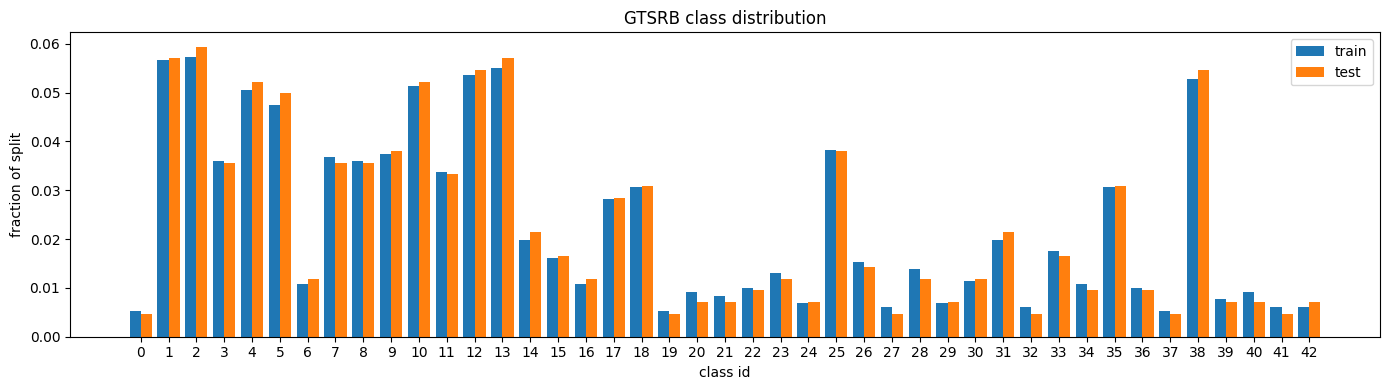

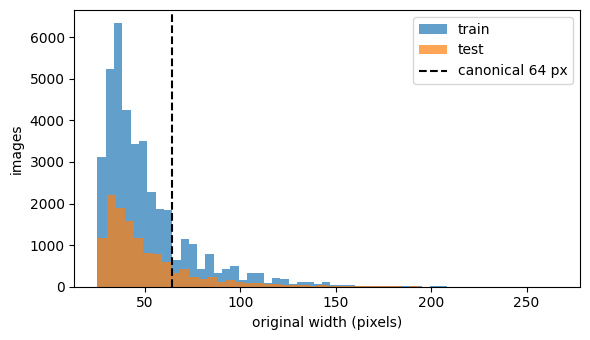

median original width: 43 px; 80% of training images are upsampled


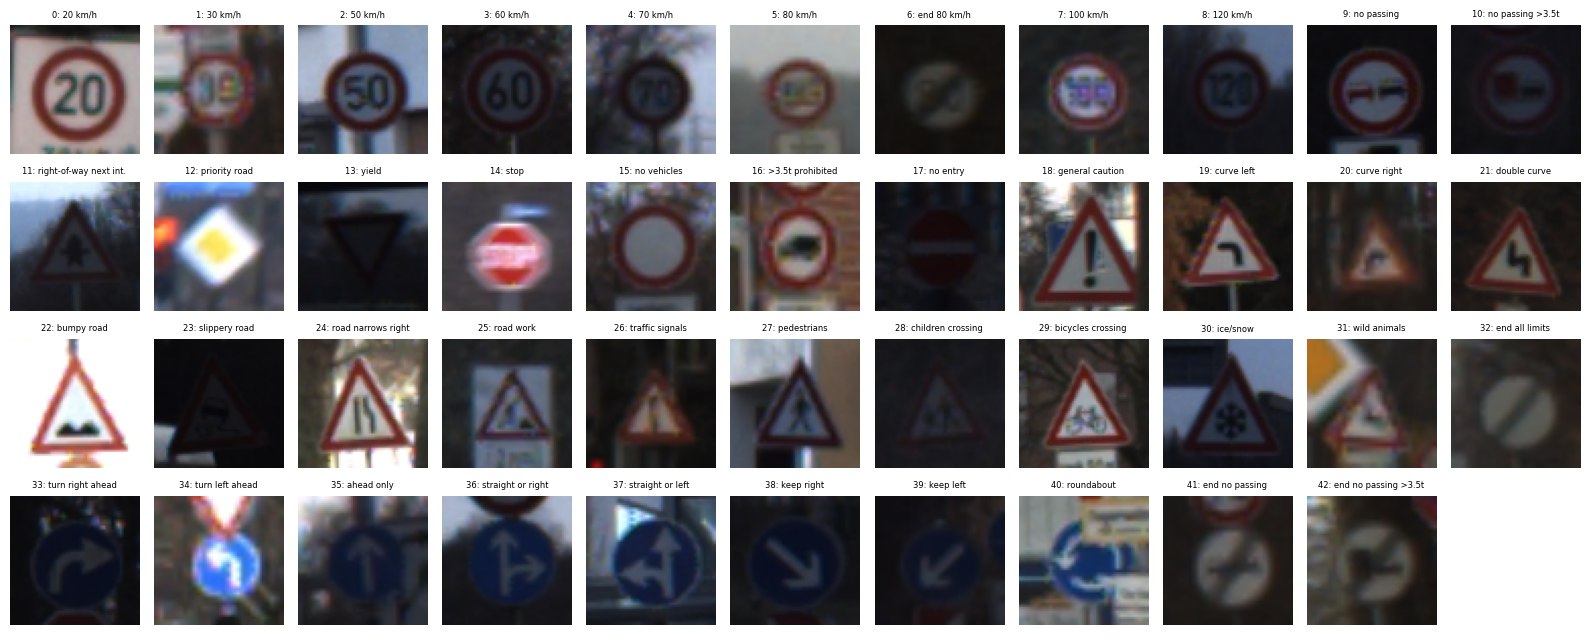

In [9]:
fig, ax = plt.subplots(figsize=(14, 4))
k = np.arange(CFG["n_classes"])
ax.bar(k - 0.2, train_counts / train_counts.sum(), 0.4, label="train")
ax.bar(k + 0.2, test_counts / test_counts.sum(), 0.4, label="test")
ax.set_xlabel("class id"); ax.set_ylabel("fraction of split"); ax.set_xticks(k)
ax.set_title("GTSRB class distribution"); ax.legend()
plt.tight_layout(); plt.savefig("figures/class_distribution.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(wh_train[:, 0], bins=50, alpha=0.7, label="train")
ax.hist(wh_test[:, 0], bins=50, alpha=0.7, label="test")
ax.axvline(CFG["img_size"], color="k", ls="--", label=f"canonical {CFG['img_size']} px")
ax.set_xlabel("original width (pixels)"); ax.set_ylabel("images"); ax.legend()
plt.tight_layout(); plt.savefig("figures/image_widths.png", dpi=150); plt.show()
print("median original width:", int(np.median(wh_train[:, 0])), "px;",
      f"{(wh_train[:, 0] < CFG['img_size']).mean():.0%} of training images are upsampled")

fig, axes = plt.subplots(4, 11, figsize=(16, 6.5))
for c, ax in zip(range(CFG["n_classes"]), axes.flat):
    ax.imshow(X_train[np.where(y_train == c)[0][len(np.where(y_train == c)[0]) // 2]])
    ax.set_title(f"{c}: {CLASS_NAMES[c]}", fontsize=6); ax.axis("off")
for ax in axes.flat[CFG["n_classes"]:]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("figures/class_examples.png", dpi=150); plt.show()

The test set has the same class proportions as training. The median original width is 43 px, so most images are *upsampled* to 64×64: these are small, blurry signs. The example grid shows what makes the task hard. Many classes differ only by a digit (the speed limits, classes 0–8) or by direction: *turn left/right ahead*, *keep left/right*, *curve left/right*.

Below are all 30 frames of one track. Ten frames of the same track are close to **one** independent example, not ten.

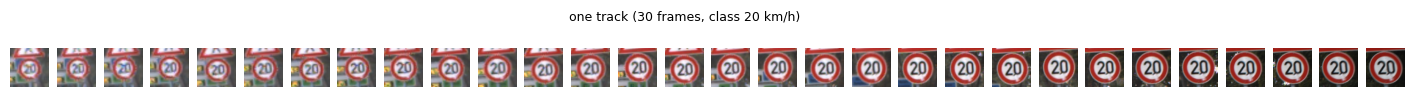

In [10]:
t = track_train[0]
frames = np.where(track_train == t)[0]
fig, axes = plt.subplots(1, len(frames), figsize=(len(frames) * 0.6, 1.2))
for ax, i in zip(np.atleast_1d(axes), frames):
    ax.imshow(X_train[i]); ax.axis("off")
plt.suptitle(f"one track ({len(frames)} frames, class {CLASS_NAMES[y_train[frames[0]]]})", fontsize=9)
plt.show()

Two consequences for the design:

- **No horizontal-flip augmentation.** Flipping turns *turn left* into *turn right*: it changes the label. For the same reason, a feature that discards orientation discards information signs need (Sections 4 and 6).
- **Validation must be split by track.** A random image-level split would put frames of the same sign on both sides, so validation would partly score near-duplicates of training images.

## 2. Protocol

The comparison is only as fair as its protocol, so the protocol is built and checked before any model sees an image.

- **Test:** the official 12,630 images. They are used once per trained model, and nothing is tuned on them.
- **Validation:** 10% of each class's *tracks*, held out entirely. Used only in Section 6, at one training size, for both methods' hyperparameters.
- **Training pool:** everything else. For each seed, one set of **nested, class-stratified** subsets is drawn from it.
  - *Nested:* the 200-image subset is inside the 500, which is inside the 1,000, and so on. Moving along the curve only adds data, rather than also re-drawing it.
  - *Stratified:* each class gets a share proportional to its frequency, with at least one image, so every subset contains all 43 classes.
  - *Shared:* at a given (size, seed), every method trains on exactly the same images, so the differences between methods are paired.

`track_split` builds the validation set and `nested_subsets` builds the training subsets.

In [11]:
def track_split(y, track, frac, seed):
    rng = np.random.RandomState(seed)
    val = []
    for c in range(CFG["n_classes"]):
        tracks_c = np.unique(track[y == c])
        n_val = max(1, int(round(frac * len(tracks_c))))
        chosen = rng.choice(tracks_c, n_val, replace=False)
        val.append(np.where(np.isin(track, chosen))[0])
    val = np.sort(np.concatenate(val))
    pool = np.setdiff1d(np.arange(len(y)), val)
    return pool, val


def nested_subsets(pool, y, sizes, seed):
    rng = np.random.RandomState(seed)
    yp = y[pool]
    counts = np.bincount(yp, minlength=CFG["n_classes"])
    p = counts / counts.sum()
    perm = {c: rng.permutation(pool[yp == c]) for c in range(CFG["n_classes"])}
    out = {}
    for N in sorted(sizes):
        q = np.minimum(np.maximum(1, np.round(N * p).astype(int)), counts)
        out[N] = np.sort(np.concatenate([perm[c][:q[c]] for c in range(CFG["n_classes"])]))
    return out


POOL, VAL = track_split(y_train, track_train, CFG["val_frac"], CFG["split_seed"])
SUBSETS = {s: nested_subsets(POOL, y_train, CFG["sizes"], s) for s in CFG["seeds"]}
print(f"pool {len(POOL):,} · validation {len(VAL):,} images "
      f"({len(np.unique(track_train[VAL]))} tracks)")
for N in CFG["sizes"]:
    idx = SUBSETS[0][N]
    print(f"N={N:>5}: actual {len(idx):>5} · min/class {np.bincount(y_train[idx], minlength=43).min():>3}"
          f" · distinct tracks {len(np.unique(track_train[idx])):>4}")

pool 35,220 · validation 3,989 images (133 tracks)
N=  200: actual   199 · min/class   1 · distinct tracks  185
N=  500: actual   504 · min/class   3 · distinct tracks  427
N= 1000: actual  1001 · min/class   5 · distinct tracks  673
N= 2000: actual  1999 · min/class  10 · distinct tracks  976
N= 5000: actual  5000 · min/class  26 · distinct tracks 1161


The pool has 35,220 images, and validation has 3,989 images from 133 tracks. Rounding moves each subset's size a little off target (199, 504, 1,001, 1,999, 5,000). At $N=200$ the rarest classes get a **single** image, which matters in Section 8. The *distinct tracks* column is the effective sample size: 185 at $N=200$ and 1,161 at $N=5000$, out of 1,174 tracks in the pool. By 5,000 almost every sign is already represented, so going further mostly adds more frames of signs already sampled.

The next cell checks the protocol with assertions rather than by eye:
- every subset is nested in the next size up;
- every subset has all 43 classes;
- no subset shares an image *or a track* with validation;
- seeds give different subsets;
- the same seed reproduces the same subset.

It writes the exact indices to `results/subsets.json`, so every training set can be reconstructed.

In [12]:
for s in CFG["seeds"]:
    sz = sorted(CFG["sizes"])
    for a, b in zip(sz, sz[1:]):
        assert np.isin(SUBSETS[s][a], SUBSETS[s][b]).all(), f"seed {s}: {a} not inside {b}"
    for N in sz:
        idx = SUBSETS[s][N]
        assert len(np.unique(y_train[idx])) == CFG["n_classes"]
        assert not np.isin(idx, VAL).any()
        assert not np.isin(track_train[idx], track_train[VAL]).any()
assert not np.array_equal(SUBSETS[0][1000], SUBSETS[1][1000])
assert np.array_equal(nested_subsets(POOL, y_train, CFG["sizes"], 0)[1000], SUBSETS[0][1000])
json.dump({str(s): {str(N): SUBSETS[s][N].tolist() for N in CFG["sizes"]} for s in CFG["seeds"]},
          open("results/subsets.json", "w"))
print("protocol checks passed · subsets written to results/subsets.json")

protocol checks passed · subsets written to results/subsets.json


One caveat about the seeds. A seed changes both *which images* are drawn and *how the network is initialised and shuffled*, so the ± reported in Section 8 contains both sources of variance. For the practical question ("I have $N$ labelled images, which method should I use?") both are real. Separating them would need a grid of subset seeds × initialisation seeds, three times the fine-tuning cost. The spreads turn out to be small (std ≤ 0.035 everywhere) compared with the gaps between methods.

## 3. Metric: macro-F1

**Macro-F1** computes F1 per class and then takes the unweighted mean over the 43 classes. Every class counts equally, however common it is. Accuracy is reported as a secondary metric.

We implement it from a confusion matrix built with one `np.bincount`, with no loop over samples. Two checks follow:

- **Hand-computed example.** `y_true = [0,0,0,0,1,1,2,2,2,2]` and `y_pred = [0,0,0,1,1,2,2,2,2,0]` give per-class F1 of 3/4, 1/2 and 3/4. Macro-F1 is therefore 2/3, while accuracy is 7/10.
- **Against scikit-learn's `f1_score(average="macro")`** on random predictions.

In [13]:
def confusion(y_true, y_pred, n=CFG["n_classes"]):
    return np.bincount(n * np.asarray(y_true) + np.asarray(y_pred), minlength=n * n).reshape(n, n)


def macro_f1(y_true, y_pred, n=CFG["n_classes"]):
    cm = confusion(y_true, y_pred, n)
    tp = np.diag(cm).astype(float)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    denom = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, denom, out=np.zeros(n), where=denom > 0)
    return f1.mean(), f1


toy_t = [0, 0, 0, 0, 1, 1, 2, 2, 2, 2]
toy_p = [0, 0, 0, 1, 1, 2, 2, 2, 2, 0]
m, per = macro_f1(toy_t, toy_p, n=3)
print("toy macro-F1:", m, "per class:", per, "(expected 0.666…; 0.75, 0.5, 0.75)")
assert abs(m - 2 / 3) < 1e-12

rng = np.random.RandomState(0)
worst = 0.0
for _ in range(20):
    yt, yp = rng.randint(0, 43, 5000), rng.randint(0, 43, 5000)
    worst = max(worst, abs(macro_f1(yt, yp)[0] -
                           f1_score(yt, yp, average="macro", labels=np.arange(43), zero_division=0)))
print("largest |ours - sklearn| over 20 random trials:", worst)

toy macro-F1: 0.6666666666666666 per class: [0.75 0.5  0.75] (expected 0.666…; 0.75, 0.5, 0.75)
largest |ours - sklearn| over 20 random trials: 0.0


The implementation matches the hand computation exactly, and differs from scikit-learn by 0.0 over 20 random trials.

**The trivial floor.** The next cell predicts the most frequent training class for every test image. A number with nothing simpler beside it is not a result.

In [14]:
maj = np.bincount(y_train[SUBSETS[0][1000]], minlength=43).argmax()
pred_maj = np.full(len(y_test), maj)
print(f"majority class: {maj} ({CLASS_NAMES[maj]})")
print(f"accuracy {accuracy_score(y_test, pred_maj):.4f} · macro-F1 {macro_f1(y_test, pred_maj)[0]:.4f}")

majority class: 1 (30 km/h)
accuracy 0.0570 · macro-F1 0.0025


Always predicting *30 km/h* gives **accuracy 0.057 but macro-F1 0.0025**. Accuracy rewards ignoring the image, because that class is common. Macro-F1 averages over 43 classes, 42 of which score 0, so it collapses. Every method below sits far above this floor.

## 4. Approach 1: classical filter bank + linear classifier

The filter bank follows Varma & Zisserman's MR8 (2005), and we build it from its definitions:

- **Edge filters:** first derivatives of an anisotropic Gaussian, at 3 scales × 6 orientations.
- **Bar filters:** second derivatives, at the same 3 scales × 6 orientations.
- **An isotropic Gaussian and a Laplacian of Gaussian.**

That gives **38 filters**. Each kernel is made zero-mean (except the Gaussian, which keeps brightness) and normalised to unit L1. Our images are 64 px rather than the ~200 px textures MR8 was designed for, so the scales are smaller: $(\sigma_\perp, \sigma_\parallel) \in \{(0.5,1.5), (1,3), (2,6)\}$, and $\sigma=2$ for the isotropic filters.

bank (38, 37, 37)


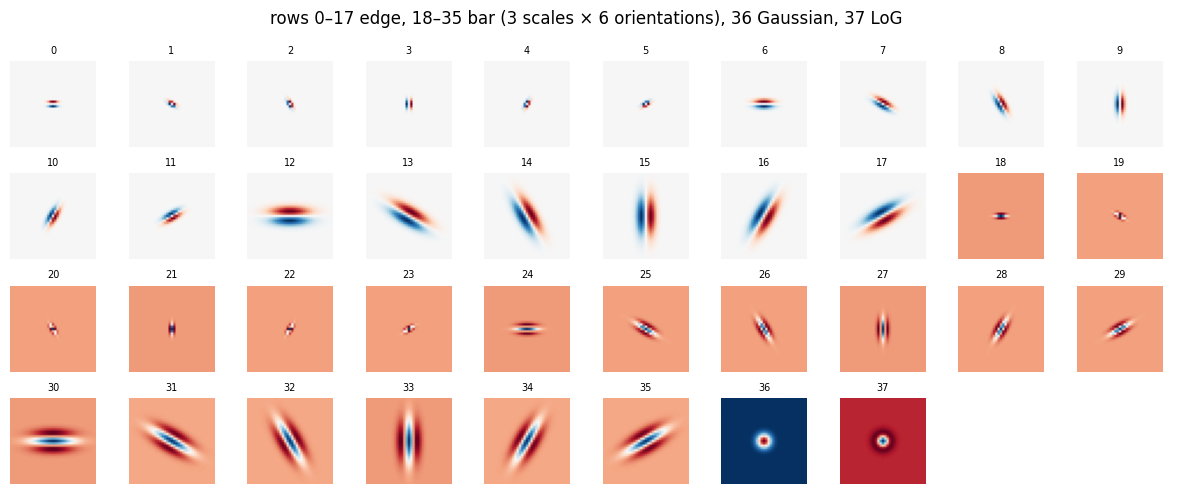

In [15]:
def gauss1d(sigma, x, order):
    g = np.exp(-x ** 2 / (2 * sigma ** 2)) / (np.sqrt(2 * np.pi) * sigma)
    if order == 0:
        return g
    if order == 1:
        return -x / sigma ** 2 * g
    return (x ** 2 - sigma ** 2) / sigma ** 4 * g


def make_bank(scales, iso_sigma, n_orient=6):
    R = int(np.ceil(3 * max([max(s) for s in scales] + [iso_sigma])))
    yy, xx = np.mgrid[-R:R + 1, -R:R + 1].astype(float)
    edges, bars = [], []
    for s_across, s_along in scales:
        for k in range(n_orient):
            th = np.pi * k / n_orient
            u = np.cos(th) * xx + np.sin(th) * yy        # along the filter
            v = -np.sin(th) * xx + np.cos(th) * yy       # across the filter
            edges.append(gauss1d(s_along, u, 0) * gauss1d(s_across, v, 1))
            bars.append(gauss1d(s_along, u, 0) * gauss1d(s_across, v, 2))
    r2 = xx ** 2 + yy ** 2
    gauss = np.exp(-r2 / (2 * iso_sigma ** 2))
    log = (r2 - 2 * iso_sigma ** 2) / iso_sigma ** 4 * gauss
    bank = np.stack(edges + bars + [gauss, log])
    for i in range(len(bank)):
        if i != len(bank) - 2:                           # the Gaussian keeps its mean (brightness)
            bank[i] -= bank[i].mean()
        bank[i] /= np.abs(bank[i]).sum()
    return bank.astype(np.float32), R


BANK, R = make_bank(CFG["mr8_scales"], CFG["mr8_iso_sigma"])
print("bank", BANK.shape)
fig, axes = plt.subplots(4, 10, figsize=(12, 5))
for ax in axes.flat:
    ax.axis("off")
for i, (ax, f) in enumerate(zip(axes.flat, BANK)):
    ax.imshow(f, cmap="RdBu_r"); ax.set_title(str(i), fontsize=7)
plt.suptitle("rows 0–17 edge, 18–35 bar (3 scales × 6 orientations), 36 Gaussian, 37 LoG")
plt.tight_layout(); plt.savefig("figures/filter_bank.png", dpi=150); plt.show()

Rows 0–17 are edge filters and 18–35 are bar filters, six orientations per scale. 36 is the Gaussian and 37 the LoG.

**Feature extraction (`filter_features`).**

1. Convert to grayscale and standardise each image to zero mean and unit variance, so brightness and contrast differences between tracks don't dominate.
2. Convolve with the bank on the GPU, with reflect padding.
3. Pick a variant:
   - `mode="mr8"` takes the maximum |response| over the 6 orientations, giving 8 rotation-invariant maps. This is MR8 proper.
   - `mode="full"` keeps all 38 maps, so orientation is kept.
4. Pool every map over a **4×4 grid**, taking both the mean |response| and the mean signed response. MR8 was designed for *textures*, where position doesn't matter. Signs are not textures, so the grid keeps *where* the structure is.

This gives 256 (MR8) or 1,216 (full) numbers per image. Features depend only on pixels and never on labels, so they are computed once for all images and indexed by subset later.

In [16]:
GRAY_W = torch.tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1)


@torch.no_grad()
def filter_features(X, mode, batch=2048, dev=DEV):
    bank, gray = torch.from_numpy(BANK)[:, None].to(dev), GRAY_W.to(dev)
    out = []
    for i in range(0, len(X), batch):
        x = torch.from_numpy(X[i:i + batch]).to(dev).permute(0, 3, 1, 2).float() / 255
        g = (x * gray).sum(1, keepdim=True)
        g = (g - g.mean((2, 3), keepdim=True)) / (g.std((2, 3), keepdim=True) + 1e-6)
        r = F.conv2d(F.pad(g, (R, R, R, R), mode="reflect"), bank)            # (B, 38, S, S)
        if mode == "mr8":
            B, _, S, _ = r.shape
            e = r[:, :18].abs().view(B, 3, 6, S, S).amax(2)
            b = r[:, 18:36].abs().view(B, 3, 6, S, S).amax(2)
            r = torch.cat([e, b, r[:, 36:]], 1)                                # (B, 8, S, S)
        G = CFG["grid"]
        f = torch.cat([F.adaptive_avg_pool2d(r.abs(), G), F.adaptive_avg_pool2d(r, G)], 1)
        out.append(f.flatten(1).cpu())
    return torch.cat(out).numpy()


t0 = time.time()
FEATS = {m: (filter_features(X_train, m), filter_features(X_test, m)) for m in CFG["feature_grid"]}
for m, (a, b) in FEATS.items():
    print(f"{m}: train {a.shape} test {b.shape}")
print(f"{time.time() - t0:.1f}s")

mr8: train (39209, 256) test (12630, 256)
full: train (39209, 1216) test (12630, 1216)
32.9s


**Classifier (`fit_linear`).** Standardise the features using statistics from the *training subset only*, then fit a multinomial logistic regression with an L2 penalty $C$ (scikit-learn). The cell below is a first check at $N=1000$, seed 0, with MR8 features and $C=1$, scored on validation. The test set is not touched.

In [17]:
def fit_linear(Ftr, ytr, C, seed=0):
    scaler = StandardScaler().fit(Ftr)
    clf = LogisticRegression(C=C, max_iter=3000, random_state=seed)
    clf.fit(scaler.transform(Ftr), ytr)
    return lambda Fx: clf.predict(scaler.transform(Fx)), clf


idx = SUBSETS[0][1000]
t0 = time.time()
predict, _ = fit_linear(FEATS["mr8"][0][idx], y_train[idx], C=1.0)
print(f"MR8 + logistic, N=1000 seed 0: val macro-F1 "
      f"{macro_f1(y_train[VAL], predict(FEATS['mr8'][0][VAL]))[0]:.4f} · {time.time() - t0:.1f}s")

MR8 + logistic, N=1000 seed 0: val macro-F1 0.3659 · 5.4s


MR8 at default settings reaches 0.366 validation macro-F1. Section 6 tunes the feature variant and $C$ so that the baseline is not a straw man. Two weaknesses remain, and we state them openly. The pipeline is **grayscale**, so it never sees sign colour (red rings vs. blue discs). And its classifier is **linear**. Stronger classical pipelines exist (e.g. HOG with colour); ours is a fair implementation of the method in our proposal.

## 5. Approach 2: fine-tuned ResNet-18

We take torchvision's ImageNet-pretrained ResNet-18 (`IMAGENET1K_V1`), **replace its 1000-way head with a 43-way linear layer**, and fine-tune *all* 11.2M weights. The rest of the architecture is unchanged.

**Input.** The same 64×64 image as the classical pipeline, upsampled on the GPU to 128×128 and normalised with ImageNet's mean and std.

**Training (`train_cnn`).**
- AdamW with weight decay $10^{-4}$, batch 64.
- A cosine learning-rate schedule.
- Mixed precision (`autocast` + `GradScaler`) for speed on the T4.

**Same compute at every size.** Every run gets exactly **1,500 optimiser steps**, whatever $N$ is: about 480 epochs at $N=200$, 19 at $N=5000$. With a fixed number of *epochs*, the large-$N$ runs would also get 25× the compute, and the curve would partly measure compute rather than data.

**No augmentation, for either method.** The classical pipeline sees each image exactly as it is, and so does the CNN.

`batches` yields an endless, epoch-shuffled stream of index batches, reproducible from the seed. `predict_cnn` runs the test set in batches of 512. The first check is one run at $N=1000$, seed 0, $lr = 3\times10^{-4}$, scored on validation.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 156MB/s]


fine-tune N=1000 seed 0: val macro-F1 0.8038 · 43s


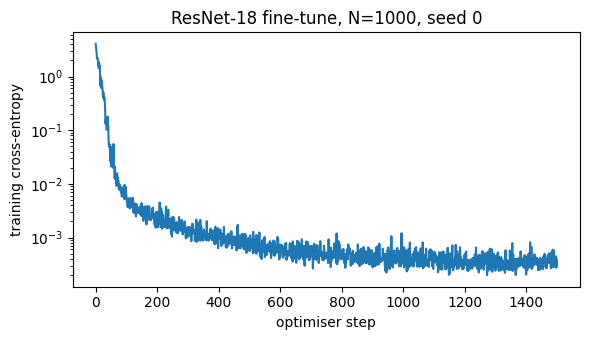

In [18]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)
X_train_t = torch.from_numpy(X_train)
X_test_t = torch.from_numpy(X_test)


def to_input(xb):
    x = xb.to(DEV, non_blocking=True).permute(0, 3, 1, 2).float() / 255
    x = F.interpolate(x, size=CFG["cnn_res"], mode="bilinear", align_corners=False)
    return (x - MEAN) / STD


def make_resnet(n_out=CFG["n_classes"]):
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(m.fc.in_features, n_out)
    return m.to(DEV)


def batches(idx, bs, seed):
    # endless epoch-shuffled stream of index batches, reproducible from the seed
    g = np.random.RandomState(seed)
    while True:
        p = g.permutation(idx)
        for i in range(0, len(p) - bs + 1, bs):
            yield p[i:i + bs]


def train_cnn(idx, seed, lr, steps=None, log=None):
    steps = steps or CFG["steps"]
    seed_everything(seed)
    model = make_resnet()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEV == "cuda")
    bs = min(CFG["batch"], len(idx))
    model.train()
    losses = []
    for step, b in zip(range(steps), batches(idx, bs, seed)):
        x = to_input(X_train_t[b])
        t = torch.from_numpy(y_train[b]).to(DEV)
        with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            loss = F.cross_entropy(model(x), t)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update(); sched.step()
        losses.append(loss.item())
        if log is not None and step % 25 == 0:
            log({"train/loss": loss.item(), "train/lr": sched.get_last_lr()[0], "step": step})
    return model, losses


@torch.no_grad()
def predict_cnn(model, Xt):
    model.eval()
    out = []
    for i in range(0, len(Xt), CFG["eval_batch"]):
        with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            out.append(model(to_input(Xt[i:i + CFG["eval_batch"]])).argmax(1).cpu())
    return torch.cat(out).numpy()


idx = SUBSETS[0][1000]
t0 = time.time()
model, losses = train_cnn(idx, seed=0, lr=3e-4)
t_train = time.time() - t0
print(f"fine-tune N=1000 seed 0: val macro-F1 "
      f"{macro_f1(y_train[VAL], predict_cnn(model, X_train_t[VAL]))[0]:.4f} · {t_train:.0f}s")
plt.figure(figsize=(6, 3.5))
plt.plot(losses); plt.yscale("log"); plt.xlabel("optimiser step"); plt.ylabel("training cross-entropy")
plt.title("ResNet-18 fine-tune, N=1000, seed 0"); plt.tight_layout(); plt.show()
del model

The training loss falls by four orders of magnitude, to about $10^{-3}$, by step ~600: the network fits its training set. That is not a problem for the comparison. The logistic regression also fits its training set, and both are judged only on the untouched test set. Validation macro-F1 is already 0.80, against 0.37 for MR8.

**Frozen linear probe (control).** Fine-tuning changes two things at once: it starts from ImageNet features *and* it adapts them. The probe isolates the first. It freezes the pretrained ResNet-18, takes its 512-d pooled features once for every image, and fits the *same* `fit_linear` as the classical pipeline. If the probe matches fine-tuning, the features are doing the work. If it falls behind, adaptation is.

In [19]:
@torch.no_grad()
def frozen_features(Xt):
    m = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1).to(DEV).eval()
    m.fc = nn.Identity()
    out = []
    for i in range(0, len(Xt), CFG["eval_batch"]):
        with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            out.append(m(to_input(Xt[i:i + CFG["eval_batch"]])).float().cpu())
    return torch.cat(out).numpy()


t0 = time.time()
PROBE = (frozen_features(X_train_t), frozen_features(X_test_t))
print("probe features", PROBE[0].shape, f"· {time.time() - t0:.0f}s")
idx = SUBSETS[0][1000]
predict, _ = fit_linear(PROBE[0][idx], y_train[idx], C=1.0)
print(f"linear probe N=1000 seed 0: val macro-F1 {macro_f1(y_train[VAL], predict(PROBE[0][VAL]))[0]:.4f}")

probe features (39209, 512) · 6s
linear probe N=1000 seed 0: val macro-F1 0.4647


## 6. Hyperparameter tuning: the same budget for each method

Each method gets a small grid, tried **once**, at $N=1000$ with seed 0, scored on the **validation tracks**. The winner is then frozen for every size and seed. Two consequences:

- **Nothing is tuned on test.**
- **Small-$N$ runs get no hidden help.** If each size were tuned separately, the 200-image runs would effectively be helped by a validation set 20× larger than their training set.

| Method | Grid | Fits |
|---|---|---|
| Classical | features {MR8, full} × $C$ {0.01, 0.1, 1, 10} | 8 |
| Linear probe | $C$ {0.01, 0.1, 1, 10} | 4 |
| Fine-tune | lr {1e-4, 3e-4, 1e-3} | 3 |

The classical pipeline gets *more* settings than the network.

In [20]:
idx = SUBSETS[0][CFG["tune_size"]]
tune_rows = []

for feat in CFG["feature_grid"]:
    for C in CFG["C_grid"]:
        predict, _ = fit_linear(FEATS[feat][0][idx], y_train[idx], C)
        tune_rows.append(dict(method="classical", features=feat, C=C,
                              val_macro_f1=macro_f1(y_train[VAL], predict(FEATS[feat][0][VAL]))[0]))
for C in CFG["C_grid"]:
    predict, _ = fit_linear(PROBE[0][idx], y_train[idx], C)
    tune_rows.append(dict(method="probe", C=C,
                          val_macro_f1=macro_f1(y_train[VAL], predict(PROBE[0][VAL]))[0]))
for lr in CFG["lr_grid"]:
    model, _ = train_cnn(idx, seed=0, lr=lr)
    tune_rows.append(dict(method="finetune", lr=lr,
                          val_macro_f1=macro_f1(y_train[VAL], predict_cnn(model, X_train_t[VAL]))[0]))
    del model

TUNE = pd.DataFrame(tune_rows)
best = lambda m: TUNE[TUNE.method == m].sort_values("val_macro_f1", ascending=False).iloc[0]
CFG["features"], CFG["C"] = best("classical")["features"], float(best("classical")["C"])
CFG["probe_C"] = float(best("probe")["C"])
CFG["lr"] = float(best("finetune")["lr"])
TUNE.to_csv("results/tuning.csv", index=False)
print(TUNE.to_string(index=False))
print("chosen:", {k: CFG[k] for k in ["features", "C", "probe_C", "lr"]})

run = wandb.init(project=CFG["wandb_project"], name=f"tuning-n{CFG['tune_size']}",
                 config=CFG, mode=CFG["wandb_mode"], job_type="tuning")
wandb.log({"tuning": wandb.Table(dataframe=TUNE.astype(str))})
run.finish()

   method features     C  val_macro_f1     lr
classical      mr8  0.01      0.221214    NaN
classical      mr8  0.10      0.329110    NaN
classical      mr8  1.00      0.365897    NaN
classical      mr8 10.00      0.366573    NaN
classical     full  0.01      0.486077    NaN
classical     full  0.10      0.532922    NaN
classical     full  1.00      0.548293    NaN
classical     full 10.00      0.531535    NaN
    probe      NaN  0.01      0.422150    NaN
    probe      NaN  0.10      0.456031    NaN
    probe      NaN  1.00      0.464708    NaN
    probe      NaN 10.00      0.466139    NaN
 finetune      NaN   NaN      0.677326 0.0001
 finetune      NaN   NaN      0.803809 0.0003
 finetune      NaN   NaN      0.907940 0.0010
chosen: {'features': 'full', 'C': 1.0, 'probe_C': 10.0, 'lr': 0.001}


**The chosen settings:** full bank with $C=1$; probe $C=10$; fine-tuning $lr=10^{-3}$. They are written into `CFG` and saved to `results/tuning.csv`.

- **The full bank beats MR8 at every $C$** (best 0.548 vs. 0.367). Throwing away orientation costs 0.18, which is the mirror-pair argument from Section 1: for signs, which way an edge points *is* the class.
- **Fine-tuning's best lr is the largest value tried**, so its true optimum may be higher. If anything, the CNN's numbers below are conservative.
- The probe's best $C$ also sits at the edge of its grid, but its curve is flat (0.464 → 0.466), so that choice doesn't matter.

## 7. The experiment

Four methods × five sizes × three seeds = 60 runs. Only the 15 fine-tuning runs need the GPU for long (~45 s each on a T4). `run_one` does four things for each run:

1. trains on `SUBSETS[seed][N]` with the settings frozen in Section 6;
2. predicts the full test set **once**;
3. appends a row to `results/results.csv` and saves the predictions to `results/preds/`, so every number in the report traces back to a file;
4. logs to W&B as `{method}-n{N}-s{seed}`, with the full `CFG` as config.

The loop is **resumable**: runs already in the CSV are skipped, so a Colab disconnect costs only the run in progress. $N=1000$ runs first, because it is the proposal's fallback result if time runs out.

*(The one-time `lr_scheduler.step()` warning in the output is harmless. Mixed precision skipped one update whose gradients overflowed in fp16, then the run continued normally.)*

In [21]:
METHODS = ["majority", "classical", "probe", "finetune"]


def run_one(method, N, seed):
    idx = SUBSETS[seed][N]
    run = wandb.init(project=CFG["wandb_project"], name=f"{method}-n{N}-s{seed}", reinit=True,
                     config={**CFG, "method": method, "N_target": N, "N": len(idx), "seed": seed},
                     mode=CFG["wandb_mode"], job_type="experiment", group=method)
    t0 = time.time()
    if method == "majority":
        pred = np.full(len(y_test), np.bincount(y_train[idx], minlength=43).argmax())
    elif method == "classical":
        Ftr, Fte = FEATS[CFG["features"]]
        predict, _ = fit_linear(Ftr[idx], y_train[idx], CFG["C"], seed)
        pred = predict(Fte)
    elif method == "probe":
        predict, _ = fit_linear(PROBE[0][idx], y_train[idx], CFG["probe_C"], seed)
        pred = predict(PROBE[1])
    elif method == "finetune":
        model, _ = train_cnn(idx, seed, CFG["lr"], log=wandb.log)
        t_fit = time.time() - t0
        pred = predict_cnn(model, X_test_t)
        del model
    t_total = time.time() - t0
    mf1, per_class = macro_f1(y_test, pred)
    row = dict(method=method, N_target=N, N=len(idx), seed=seed, macro_f1=mf1,
               accuracy=accuracy_score(y_test, pred), seconds=t_total)
    np.save(f"results/preds/{method}_n{N}_s{seed}.npy", pred.astype(np.int16))
    wandb.log({"test/macro_f1": mf1, "test/accuracy": row["accuracy"], "seconds": t_total,
               "test/per_class_f1": wandb.Histogram(per_class)})
    run.summary.update(row)
    run.finish()
    pd.DataFrame([row]).to_csv(CFG["results_csv"], mode="a", index=False,
                               header=not os.path.exists(CFG["results_csv"]))
    return row


done = set()
if os.path.exists(CFG["results_csv"]):
    prev = pd.read_csv(CFG["results_csv"])
    done = set(zip(prev.method, prev.N_target, prev.seed))
todo = [(m, N, s) for N in CFG["run_order"] for s in CFG["seeds"] for m in METHODS
        if (m, N, s) not in done]
print(f"{len(done)} runs already done · {len(todo)} to go")
for m, N, s in todo:
    r = run_one(m, N, s)
    print(f"{m:>9}  N={r['N']:>5}  seed {s}  macro-F1 {r['macro_f1']:.4f}  acc {r['accuracy']:.4f}"
          f"  ({r['seconds']:.0f}s)")

0 runs already done · 60 to go


 majority  N= 1001  seed 0  macro-F1 0.0025  acc 0.0570  (0s)


classical  N= 1001  seed 0  macro-F1 0.5575  acc 0.6709  (6s)


    probe  N= 1001  seed 0  macro-F1 0.4509  acc 0.5838  (1s)


 finetune  N= 1001  seed 0  macro-F1 0.9304  acc 0.9558  (45s)


...

 finetune  N= 1999  seed 1  macro-F1 0.9571  acc 0.9732  (45s)


 majority  N= 1999  seed 2  macro-F1 0.0025  acc 0.0570  (0s)


classical  N= 1999  seed 2  macro-F1 0.6502  acc 0.7432  (10s)


    probe  N= 1999  seed 2  macro-F1 0.5666  acc 0.6550  (1s)


 finetune  N= 1999  seed 2  macro-F1 0.9681  acc 0.9794  (44s)


## 8. Results

All 60 runs completed. The table below is built from `results/results.csv` alone and saved as `results/summary.csv`: test macro-F1, mean ± std over the 3 seeds.

In [22]:
R_ = pd.read_csv(CFG["results_csv"])
summary = (R_.groupby(["method", "N_target"])
             .agg(N=("N", "mean"), runs=("seed", "count"),
                  f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
                  acc_mean=("accuracy", "mean"), acc_std=("accuracy", "std"))
             .reset_index())
summary.to_csv("results/summary.csv", index=False)
pm = lambda m, s: f"{m:.3f} ± {s:.3f}"
table = summary.assign(cell=[pm(a, b) for a, b in zip(summary.f1_mean, summary.f1_std)]) \
               .pivot(index="N_target", columns="method", values="cell")
print("macro-F1 (mean ± std over seeds)"); print(table[[m for m in METHODS if m in table]].to_string())

macro-F1 (mean ± std over seeds)
method         majority      classical          probe       finetune
N_target                                                            
200       0.003 ± 0.000  0.317 ± 0.026  0.303 ± 0.015  0.478 ± 0.035
500       0.003 ± 0.000  0.457 ± 0.010  0.428 ± 0.024  0.789 ± 0.019
1000      0.003 ± 0.000  0.562 ± 0.007  0.477 ± 0.033  0.925 ± 0.021
2000      0.003 ± 0.000  0.659 ± 0.022  0.545 ± 0.021  0.963 ± 0.006
5000      0.003 ± 0.000  0.753 ± 0.006  0.603 ± 0.008  0.981 ± 0.006


Next, the figure the project exists to produce. **Left:** test macro-F1 against training-set size (log scale), with ±1 std error bars. **Right:** the **paired gap**. Both methods saw the same images at a given seed, so we take the difference per seed and then average. The gaps are saved to `results/gap_*.csv`.

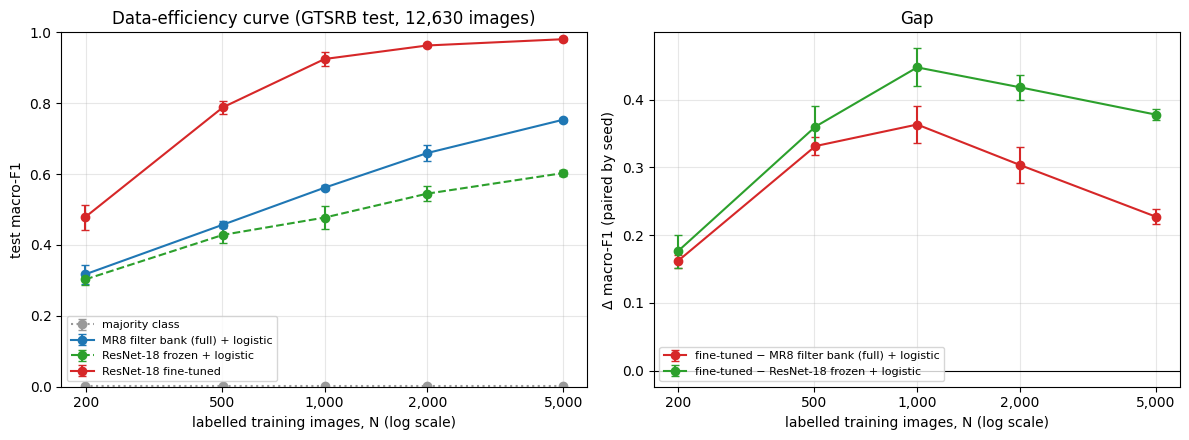

In [23]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
style = dict(majority=("0.6", ":"), classical=("C0", "-"), probe=("C2", "--"), finetune=("C3", "-"))
label = dict(majority="majority class", classical=f"MR8 filter bank ({CFG['features']}) + logistic",
             probe="ResNet-18 frozen + logistic", finetune="ResNet-18 fine-tuned")
for m in METHODS:
    s = summary[summary.method == m].sort_values("N")
    if len(s):
        a1.errorbar(s.N, s.f1_mean, yerr=s.f1_std, marker="o", capsize=3,
                    color=style[m][0], ls=style[m][1], label=label[m])
a1.set_xscale("log"); a1.set_xlabel("labelled training images, N (log scale)")
a1.set_ylabel("test macro-F1"); a1.set_ylim(0, 1); a1.grid(alpha=0.3); a1.legend(fontsize=8)
a1.set_title("Data-efficiency curve (GTSRB test, 12,630 images)")

wide = R_.pivot_table(index=["N_target", "seed"], columns="method", values="macro_f1")
for other, col in [("classical", "C3"), ("probe", "C2")]:
    if {"finetune", other} <= set(wide.columns):
        gap = (wide["finetune"] - wide[other]).groupby("N_target").agg(["mean", "std"])
        n_actual = summary[summary.method == "finetune"].set_index("N_target").N.loc[gap.index]
        a2.errorbar(n_actual, gap["mean"], yerr=gap["std"], marker="o", capsize=3, color=col,
                    label=f"fine-tuned − {label[other]}")
        gap.to_csv(f"results/gap_finetune_minus_{other}.csv")
a2.axhline(0, color="k", lw=0.8); a2.set_xscale("log")
a2.set_xlabel("labelled training images, N (log scale)"); a2.set_ylabel("Δ macro-F1 (paired by seed)")
a2.set_title("Gap"); a2.grid(alpha=0.3); a2.legend(fontsize=8)
for a in (a1, a2):
    a.set_xticks(CFG["sizes"]); a.set_xticklabels([f"{n:,}" for n in CFG["sizes"]]); a.minorticks_off()
plt.tight_layout(); plt.savefig("figures/data_efficiency.png", dpi=200); plt.show()

### Findings

**1. The CNN is ahead at every size (hypothesis part 1: supported).** Fine-tuning beats the classical pipeline at every $N$ and on every seed. The smallest single-seed gap is +0.152.

**2. The gap is not widest at low data (hypothesis part 2: contradicted).**

| $N$ | Fine-tuned − classical (paired) |
|---|---|
| 200 | +0.161 ± 0.009 |
| 500 | +0.331 ± 0.014 |
| 1000 | **+0.363 ± 0.028** |
| 2000 | +0.304 ± 0.026 |
| 5000 | +0.227 ± 0.011 |

The gap is an inverted U: smallest with the least data, peaking at 1,000, shrinking as the network nears its ceiling (0.981). We see two reasons for the collapse at $N=200$. Some classes get a single training image, which no method can learn from. And 11M parameters fitted to 199 images is fine-tuning's weakest regime.

**3. Data efficiency.** Fine-tuned on **500 images (0.789)**, the network beats the classical pipeline trained on **5,000 (0.753)**: ten times fewer labels for a better score.

**4. The advantage comes from fine-tuning, not from ImageNet features alone.** The frozen probe roughly ties the classical pipeline at $N=200$ (0.303 vs. 0.317), then falls behind (0.603 vs. 0.753 at $N=5000$). Frozen ImageNet features from 64-px signs do not separate these classes linearly. Adapting them adds 0.18–0.45. One caveat: ImageNet features are learned at 224 px, so a probe at higher resolution might do better.

**Accuracy vs. macro-F1.** The next cell prints the accuracy table and how much accuracy exceeds macro-F1.

In [24]:
acc_tab = summary.assign(cell=[pm(a, b) for a, b in zip(summary.acc_mean, summary.acc_std)]) \
                 .pivot(index="N_target", columns="method", values="cell")
print("accuracy (mean ± std over seeds)"); print(acc_tab[[m for m in METHODS if m in acc_tab]].to_string())
d = summary.assign(acc_minus_f1=summary.acc_mean - summary.f1_mean)
print(d.pivot(index="N_target", columns="method", values="acc_minus_f1").round(3).to_string())

accuracy (mean ± std over seeds)
method         majority      classical          probe       finetune
N_target                                                            
200       0.057 ± 0.000  0.428 ± 0.010  0.430 ± 0.009  0.641 ± 0.044
500       0.057 ± 0.000  0.563 ± 0.008  0.552 ± 0.013  0.887 ± 0.004
1000      0.057 ± 0.000  0.668 ± 0.004  0.593 ± 0.020  0.953 ± 0.009
2000      0.057 ± 0.000  0.746 ± 0.008  0.642 ± 0.011  0.976 ± 0.003
5000      0.057 ± 0.000  0.818 ± 0.003  0.687 ± 0.003  0.986 ± 0.004
method    classical  finetune  majority  probe
N_target                                      
200           0.111     0.163     0.054  0.127
500           0.106     0.098     0.054  0.123
1000          0.107     0.029     0.054  0.116
2000          0.086     0.013     0.054  0.098
5000          0.065     0.006     0.054  0.084


Accuracy gives the same ranking but flatters every method. Proportional stratification gives rare classes very few training images, and accuracy barely notices failures on rare classes.

- **Classical pipeline:** accuracy exceeds macro-F1 by ~0.11 up to $N=1000$, narrowing to 0.065 at $N=5000$.
- **Fine-tuned network:** the excess is 0.163 at $N=200$ and almost nothing (0.006) at $N=5000$, once it gets the rare classes right too.

## 9. Cost

The proposal promised model size and latency alongside accuracy:
- parameters and fp32 size;
- CPU latency at batch 1;
- GPU throughput at batch 512;
- mean training wall-clock, from `results.csv`.

In [25]:
def timeit(fn, reps):
    fn()  # warm-up
    if DEV == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps): fn()
    if DEV == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / reps

n_feat = FEATS[CFG["features"]][0].shape[1]
params = {
    "classical": BANK.size + n_feat * CFG["n_classes"] + CFG["n_classes"] + 2 * n_feat,
    "probe": sum(p.numel() for p in resnet18().parameters()) - 1000 * 513 + 512 * 43 + 43 + 2 * 512,
    "finetune": sum(p.numel() for p in make_resnet().parameters()),
}

# CPU, batch 1: classical = filter bank + pooling + the fitted linear model; CNN = forward pass
idx = SUBSETS[0][1000]
predict_cls, _ = fit_linear(FEATS[CFG["features"]][0][idx], y_train[idx], CFG["C"])
one = X_test[:1]
net_cpu = resnet18(); net_cpu.fc = nn.Linear(512, 43); net_cpu.eval()
x_cpu = torch.randn(1, 3, CFG["cnn_res"], CFG["cnn_res"])
with torch.no_grad():
    lat = {"classical": timeit(lambda: predict_cls(filter_features(one, CFG["features"], dev="cpu")), 50),
           "finetune": timeit(lambda: net_cpu(x_cpu), 20)}
lat["probe"] = lat["finetune"]

gpu_tp = {}
if DEV == "cuda":
    xb = X_test[:512]
    gpu_tp["classical"] = 512 / timeit(lambda: filter_features(xb, CFG["features"]), 5)
    net = make_resnet().eval()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        gpu_tp["finetune"] = 512 / timeit(lambda: net(to_input(X_test_t[:512])), 5)
    gpu_tp["probe"] = gpu_tp["finetune"]

tt = R_.groupby(["method", "N_target"]).seconds.mean().unstack()
cost = pd.DataFrame({
    "parameters": params,
    "size_MB_fp32": {k: v * 4 / 1e6 for k, v in params.items()},
    "cpu_ms_per_image_b1": {k: v * 1e3 for k, v in lat.items()},
    "gpu_images_per_s_b512": gpu_tp,
    "train_s_N1000": tt.get(1000, pd.Series(dtype=float)).to_dict(),
    "train_s_N5000": tt.get(5000, pd.Series(dtype=float)).to_dict(),
})
cost = cost.drop(index="majority", errors="ignore")
cost.to_csv("results/cost.csv")
print(cost.round(2).to_string())

           parameters  size_MB_fp32  cpu_ms_per_image_b1  gpu_images_per_s_b512  train_s_N1000  train_s_N5000
classical    106785.0          0.43                98.46                3152.24           5.95          15.79
probe      11199595.0         44.80                24.99                8906.23           0.71           4.63
finetune   11198571.0         44.79                24.99                8906.23          45.20          46.98


**What the cost table shows.**

- **Size:** the classical model is **105× smaller** (107k parameters, 0.43 MB, vs. 11.2M and 44.8 MB).
- **Training time:** seconds instead of ~45 s per run.
- **Inference speed:** as implemented, it is **slower**, at 98 ms vs. 25 ms per image on CPU and 3,152 vs. 8,906 images/s on GPU.

The slowness belongs to our implementation, not the method. We run 38 dense 37×37 convolutions directly. Separable or FFT filtering would cut this substantially, while ResNet's small 3×3 kernels are heavily optimised. The honest trade-off is therefore **memory, not speed**.

## 10. Where each method fails

A mean over 43 classes hides which classes carry the gap. Below is the per-class F1 at $N=1000$, seed 0, sorted by the gap between the two methods.

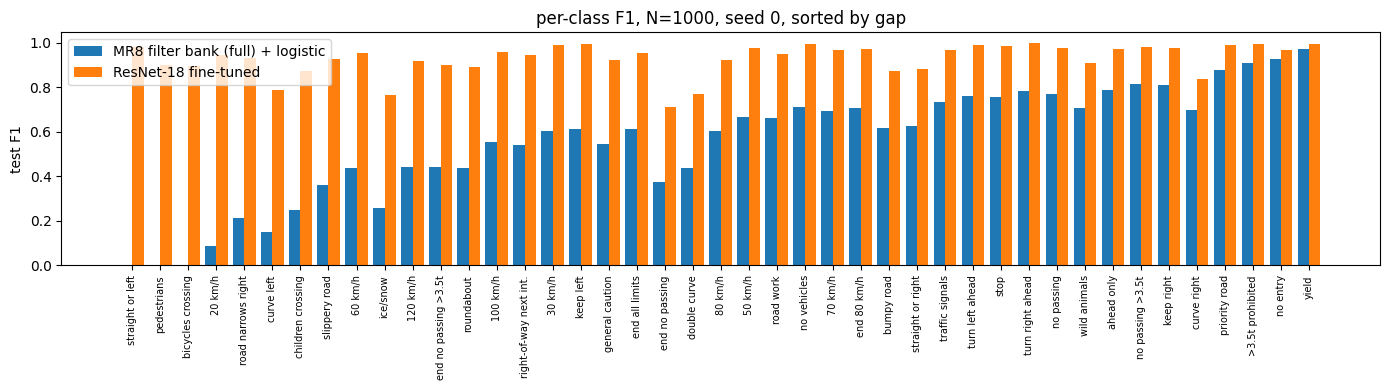

        straight or left: classical 0.000 · fine-tuned 0.983 · train images at N=1000: 5
             pedestrians: classical 0.000 · fine-tuned 0.903 · train images at N=1000: 6
       bicycles crossing: classical 0.000 · fine-tuned 0.898 · train images at N=1000: 7
                 20 km/h: classical 0.086 · fine-tuned 0.945 · train images at N=1000: 5
      road narrows right: classical 0.212 · fine-tuned 0.931 · train images at N=1000: 7


In [26]:
N0, s0 = 1000, 0
pc = {m: macro_f1(y_test, np.load(f"results/preds/{m}_n{N0}_s{s0}.npy"))[1]
      for m in ["classical", "finetune"] if os.path.exists(f"results/preds/{m}_n{N0}_s{s0}.npy")}
if len(pc) == 2:
    order = np.argsort(pc["finetune"] - pc["classical"])[::-1]
    fig, ax = plt.subplots(figsize=(14, 4))
    k = np.arange(CFG["n_classes"])
    ax.bar(k - 0.2, pc["classical"][order], 0.4, label=label["classical"])
    ax.bar(k + 0.2, pc["finetune"][order], 0.4, label=label["finetune"])
    ax.set_xticks(k); ax.set_xticklabels([CLASS_NAMES[i] for i in order], rotation=90, fontsize=7)
    ax.set_ylabel("test F1"); ax.set_title(f"per-class F1, N={N0}, seed {s0}, sorted by gap")
    ax.legend(); plt.tight_layout(); plt.savefig("figures/per_class_f1.png", dpi=150); plt.show()
    for i in order[:5]:
        print(f"{CLASS_NAMES[i]:>24}: classical {pc['classical'][i]:.3f} · fine-tuned {pc['finetune'][i]:.3f}"
              f" · train images at N={N0}: {np.bincount(y_train[SUBSETS[s0][N0]], minlength=43)[i]}")

The classical pipeline scores **F1 = 0** on three rare classes: *straight or left*, *pedestrians* and *bicycles crossing*, each with only 5–7 training images at $N=1000$. The fine-tuned network gets 0.90–0.98 on the same classes.

The other failure is the speed limits. Below are row-normalised confusion matrices for the nine speed-limit classes, with three test images from the classical pipeline's most frequent confusion.

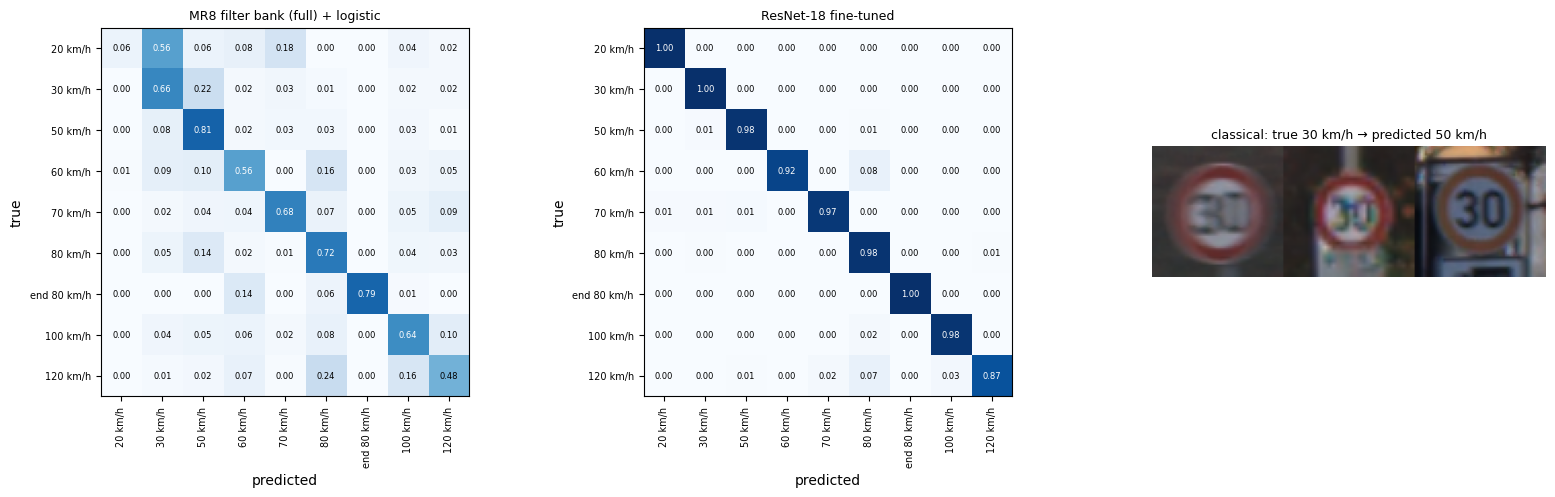

In [27]:
SL = list(range(9))
if len(pc) == 2:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw=dict(width_ratios=[1, 1, 0.9]))
    for ax, m in zip(axes, ["classical", "finetune"]):
        p = np.load(f"results/preds/{m}_n{N0}_s{s0}.npy")
        cm = confusion(y_test, p)[np.ix_(SL, SL)].astype(float)
        cm /= np.maximum(cm.sum(1, keepdims=True), 1)
        ax.imshow(cm, vmin=0, vmax=1, cmap="Blues")
        for i in SL:
            for j in SL:
                ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=6,
                        color="w" if cm[i, j] > 0.5 else "k")
        ax.set_xticks(SL); ax.set_yticks(SL)
        ax.set_xticklabels([CLASS_NAMES[i] for i in SL], rotation=90, fontsize=7)
        ax.set_yticklabels([CLASS_NAMES[i] for i in SL], fontsize=7)
        ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(label[m], fontsize=9)
    p = np.load(f"results/preds/classical_n{N0}_s{s0}.npy")
    cm = confusion(y_test, p)[np.ix_(SL, SL)]; np.fill_diagonal(cm, 0)
    ti, pj = np.unravel_index(cm.argmax(), cm.shape)
    wrong = np.where((y_test == ti) & (p == pj))[0][:3]
    axes[2].imshow(np.concatenate([X_test[i] for i in wrong], 1) if len(wrong) else np.zeros((8, 8)))
    axes[2].set_title(f"classical: true {CLASS_NAMES[ti]} → predicted {CLASS_NAMES[pj]}", fontsize=9)
    axes[2].axis("off")
    plt.tight_layout(); plt.savefig("figures/speed_limit_confusion.png", dpi=150); plt.show()

**The classical pipeline confuses neighbouring speed limits.**

- 56% of *20 km/h* signs are predicted as *30*, and only 6% are correct. It is also the rarest class.
- 24% of *120* are predicted as *80*, and 16% as *100*.
- 22% of *30* are predicted as *50*.

The fine-tuned network is nearly diagonal. Its worst speed-limit class is *120 km/h*, at 0.87.

The example images show why. The red ring, white disc and layout are identical across these classes, and only a few pixels of digit shape differ at 64 px. Averaging filter energy over a 4×4 grid blurs exactly that shape away, while a CNN learns detectors for the digit strokes.

### Limitations

- The classical pipeline is grayscale and linear (Section 4).
- The seed mixes subset and initialisation variance (Section 2).
- Beyond $N≈2000$ the curve adds frames of signs already sampled rather than new signs.
- The results are for one dataset (GTSRB) and one architecture (ResNet-18).

### What we would do next

Strengthen the **baseline**, not the network: add colour and HOG features to the classical pipeline and rerun the same protocol. If such a model came within the error bars of fine-tuning at $N \le 500$, our conclusion would shrink from "pretraining is what you need when labels are scarce" to "MR8 was the wrong classical feature". It needs no GPU and runs in minutes.

## 11. Experiment tracking

Every run is logged to Weights & Biases, with the full `CFG` as its config: [wandb.ai/2729931-wits-university/coms4036a-gtsrb](https://wandb.ai/2729931-wits-university/coms4036a-gtsrb). Runs are grouped by method, and the tuning run is `tuning-n1000`. The same numbers are in `results/` in this repository.
